# Detecção e Classificação de Placas de Trânsito

**Processamento de Imagem e Visão Computacional — Mestrado em Computação Aplicada (UFABC)**

---

## 1. Objetivo

Construir um sistema capaz de **localizar** uma placa de trânsito circular em uma imagem e **classificá-la** entre 6 categorias, usando técnicas de processamento de imagem para a detecção (transformada de Hough) e redes neurais para a classificação.

O problema vem de uma aplicação real: um robô móvel com câmera precisa reconhecer placas para decidir para onde virar. Aqui o escopo foi reduzido ao que interessa à disciplina — **a cadeia de processamento da imagem**.

## 2. Pipeline

```
                    ┌─────────────────────── TREINO (offline) ──────────────────────┐
6 imagens de  ──►   augmentation                    ──►   dataset    ──►   3 redes
  referência        (geométrico + fotométrico)            (2400          (MLP, CNN,
                                                          imagens)       CNN+pooling)

                    ┌─────────────────────── INFERÊNCIA (online) ───────────────────┐
   imagem     ──►  cinza  ──►  mediana  ──►  Hough  ──►  bounding  ──►  Otsu +   ──►  rede  ──►  classe
   colorida                                (círculos)      box          máscara
```

As duas pontas precisam produzir imagens comparáveis: se o treino vê uma distribuição diferente da que a câmera entrega, o modelo aprende algo que nunca vai encontrar em operação. Aqui isso é obtido **pelo enquadramento**, e não por replicar toda a cadeia — as imagens de referência já vêm recortadas rentes à placa, com margem equivalente à que o recorte da Hough produz. A Seção 4.5 exibe as duas lado a lado para conferência.

## 3. Classes

As 6 placas de referência (`PL1.png` … `PL6.png`) correspondem a placas circulares de regulamentação: sentido obrigatório (frente, esquerda, direita) e suas versões de proibição.

## 4. Antes de rodar

- **Ative a GPU**: `Ambiente de execução → Alterar o tipo de ambiente de execução → T4 GPU`. Uma das arquiteturas testadas (CNN sem pooling) tem ~100 milhões de parâmetros e fica lenta em CPU.
- Faça o upload de `PL1.png` … `PL6.png` quando a célula da Seção 1 pedir.
- Execução completa: aproximadamente 5–10 minutos na GPU.

---
# Seção 0 — Configuração

Importações, constantes globais e fixação das sementes aleatórias.

Três constantes definem toda a geometria do projeto e aparecem em todas as seções:

| Constante | Valor | Significado |
|---|---|---|
| `TAM` | 80 | lado da imagem que entra na rede (80×80 px, tons de cinza) |
| `MARGEM` | 0.25 | margem extra ao redor do círculo detectado, em frações do raio |
| `RAIO_MASCARA` | 32 | raio do círculo da placa dentro da imagem de 80×80 |

`RAIO_MASCARA` não é um valor arbitrário: é consequência dos outros dois. Se recortamos a placa com 25% de margem e redimensionamos para 80×80, a placa ocupa `80 / (2 · 1,25) = 32` px de raio. É esse raio que a máscara circular da Seção 4.5 usa para separar a placa do fundo da cena.

In [11]:
import os
import math
import time
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# ---------------------------------------------------------------- reprodutibilidade
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)
rng = np.random.default_rng(SEMENTE)

# ---------------------------------------------------------------- geometria
TAM = 80                              # lado da imagem de entrada da rede
MARGEM = 0.25                         # margem ao redor do círculo, em frações do raio
RAIO_MASCARA = TAM / (2 * (1 + MARGEM))   # = 32 px

# ---------------------------------------------------------------- classes
# ATENÇÃO: esta ordem precisa corresponder exatamente à ordem dos arquivos
# PL1.png ... PL6.png. Confira visualmente na Seção 1.1 antes de reportar
# qualquer resultado.
NOMES = [
    "R-25a_esquerda",
    "R-25b_direita",
    "R-26_frente",
    "R-3_sentido-proibido",
    "R-4a_proibido-esquerda",
    "R-4b_proibido-direita",
]
N_CLASSES = len(NOMES)

print('OpenCV     :', cv2.__version__)
print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU') or 'nenhuma (o treino vai ficar lento)')

OpenCV     : 5.0.0
TensorFlow : 2.20.0
GPU        : nenhuma (o treino vai ficar lento)


### 0.1 — Função auxiliar de visualização

No Colab não existe janela de sistema, então `cv2.imshow` não funciona. Todas as visualizações usam `matplotlib`. A função abaixo cuida da conversão BGR→RGB (OpenCV usa BGR, matplotlib espera RGB) e da escala de cinza fixa em 0–255, para que imagens binarizadas não sejam normalizadas automaticamente e pareçam ter mais níveis do que realmente têm.

In [12]:
def mostra(imagens, titulos=None, colunas=3, tam=3.0):
    """Exibe uma lista de imagens (cinza ou BGR) em uma grade."""
    n = len(imagens)
    linhas = math.ceil(n / colunas)
    fig, eixos = plt.subplots(linhas, colunas, figsize=(colunas * tam, linhas * tam))
    eixos = np.atleast_1d(np.array(eixos)).reshape(-1)
    for i, ax in enumerate(eixos):
        ax.axis('off')
        if i < n:
            img = imagens[i]
            if img.ndim == 3:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            else:
                ax.imshow(img, cmap='gray', vmin=0, vmax=255)
            if titulos is not None:
                ax.set_title(titulos[i], fontsize=10)
    plt.tight_layout()
    plt.show()

---
# Seção 1 — Criação do dataset

Não existe base de dados pronta: o dataset inteiro é sintetizado a partir de **6 imagens de referência**, uma por classe. Isso é comum em aplicações fechadas como esta, onde o conjunto de objetos a reconhecer é pequeno, conhecido de antemão e padronizado por norma.

A geração é deliberadamente simples — **escala de cinza, redimensionamento para 80×80 e augmentation**. Nada de binarização ou operadores morfológicos aqui.

A razão é geométrica: as imagens de referência já vêm recortadas rentes à placa, com margem de cerca de 13%, enquanto o recorte da Hough usa 25%. Medindo o raio do disco branco nos dois casos depois do redimensionamento para 80×80, dá **23,4 px** no treino contra **24,5 px** na inferência — 4% de diferença. O enquadramento já está alinhado, então qualquer processamento extra na criação do dataset só destruiria informação.

### 1.1 — Carregamento e inspeção das referências

Duas coisas a conferir na saída abaixo.

**A ordem das classes.** Confira se a sequência das imagens bate com a lista `NOMES` da Seção 0. Um erro aqui contamina silenciosamente todo o resto: o modelo treina perfeitamente e reporta a classe errada.

**O fundo.** Nestes arquivos, a área fora da placa é **preta** (nível 0), não branca. Isso não é um detalhe cosmético: define o valor de preenchimento nas transformações geométricas da Seção 1.2 (se o preenchimento fosse branco, cada rotação ou redução de escala criaria um arco branco espúrio na borda) e explica a aparência do dataset gerado.

Para baixar arquivos do Google Drive, usaremos a biblioteca `gdown`. Primeiramente, instale-a:

In [13]:
pip install gdown

Após o download, os arquivos `PL1.png` a `PL6.png` devem estar disponíveis dentro do seu ambiente de execução do Colab.

In [14]:
import gdown

# ID da pasta do Google Drive fornecida pelo usuário
folder_id = '1TfB_mU4a4AkYxIswqlki1MrLpUJm2ead'

# Baixar os arquivos da pasta
print(f"Baixando arquivos da pasta do Google Drive (ID: {folder_id})...")
gdown.download_folder(id=folder_id, quiet=False)
print("Download concluído!")

Baixando arquivos da pasta do Google Drive (ID: 1TfB_mU4a4AkYxIswqlki1MrLpUJm2ead)...


Retrieving folder contents


Processing file 1OfymOGmt_fM0HXpxjSO2bLq1_2r4Tp8_ PL1.png
Processing file 1SgIUliyo8huNyP0xs3KUZAaw0GhtADF5 PL2.png
Processing file 1fd7xugNr_u1JlZhneFDMd_S9QWG5OP98 PL3.png
Processing file 1YX80sZDlYROj49sKo4DXQ6wl_93yIbMb PL4.png
Processing file 1n9ECgV4-2AFtaNf_n_EKDr3JvKfwNFUM PL5.png
Processing file 1i0PUU_DSBAR5huOAkces71H6vrTnWmjj PL6.png


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1OfymOGmt_fM0HXpxjSO2bLq1_2r4Tp8_
To: /content/Dataset/PL1.png
100%|██████████| 32.0k/32.0k [00:00<00:00, 53.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1SgIUliyo8huNyP0xs3KUZAaw0GhtADF5
To: /content/Dataset/PL2.png
100%|██████████| 38.7k/38.7k [00:00<00:00, 41.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1fd7xugNr_u1JlZhneFDMd_S9QWG5OP98
To: /content/Dataset/PL3.png
100%|██████████| 38.2k/38.2k [00:00<00:00, 62.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1YX80sZDlYROj49sKo4DXQ6wl_93yIbMb
To: /content/Dataset/PL4.png
100%|██████████| 44.5k/44.5k [00:00<00:00, 60.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1n9ECgV4-2AFtaNf_n_EKDr3JvKfwNFUM
To: /content/Dataset/PL5.png
100%|██████████| 55.4k/55.4k [00:00<00:00, 66.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1i0

Download concluído!



Download completed


nível de cinza do canto superior esquerdo (fundo): [0, 0, 0, 0, 0, 0]


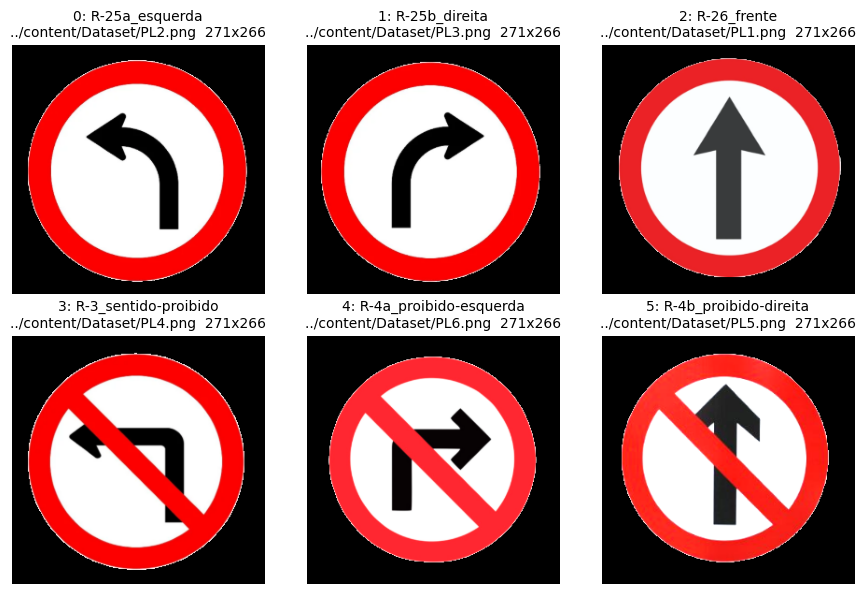

In [15]:
# PL1=frente(R-26)  PL2=esquerda(R-25a)  PL3=direita(R-25b)
# PL4=proibido-esquerda(R-4a)  PL5=sentido-proibido(R-3)  PL6=proibido-direita(R-4b)
'''
CLASSES_FINAIS = [
    "R-25a_esquerda",
    "R-25b_direita",
    "R-26_frente",
    "R-3_sentido-proibido",
    "R-4a_proibido-esquerda",
    "R-4b_proibido-direita",
]
'''

ORDEM_PL = [2, 3, 1, 4, 6, 5]     # indice canonico -> numero do arquivo
CAMINHOS = [f"../content/Dataset/PL{n}.png" for n in ORDEM_PL]
faltando = [c for c in CAMINHOS if not os.path.exists(c)]

if faltando:
    raise FileNotFoundError(f'Faltam os arquivos: {faltando}. Verifique se o download foi concluído corretamente.')

referencias_bgr = [cv2.imread(c) for c in CAMINHOS]
assert all(img is not None for img in referencias_bgr), 'Alguma referência não pôde ser lida.'

# Máscara do que é placa (o resto é fundo). Usada na Seção 4 para montar cenas de teste.
REF_MASCARA = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) > 20 for im in referencias_bgr]

print('nível de cinza do canto superior esquerdo (fundo):',
      [int(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)[0, 0]) for im in referencias_bgr])

mostra(referencias_bgr,
       [f'{i}: {NOMES[i]}\n{CAMINHOS[i]}  {referencias_bgr[i].shape[1]}x{referencias_bgr[i].shape[0]}'
        for i in range(N_CLASSES)],
       colunas=3)

### 1.2 — Augmentation

Com 6 imagens apenas, o augmentation é o que transforma o problema em algo treinável. Cada transformação foi escolhida para corresponder a uma fonte concreta de variação no sistema real, e não por ser uma opção disponível na biblioteca:

| Transformação | Faixa | O que simula |
|---|---|---|
| Rotação | ±5° | placa torta no suporte, câmera não nivelada |
| Escala | ±20% | distância variável entre a câmera e a placa |
| Deslocamento | ±3 px | erro de centralização do círculo estimado pela Hough |
| Brilho | ±30 níveis | iluminação do ambiente |
| Desfoque gaussiano | k ∈ {1, 3, 5} | desfoque de movimento e de foco |
| Ruído gaussiano | σ = 8 | ruído do sensor, sobretudo com pouca luz |

As três primeiras são **transformações geométricas**, aplicadas por uma única matriz afim 2×3 combinando rotação, escala e translação — uma composição só, e portanto uma única interpolação, o que evita o borramento acumulado de aplicar três `warpAffine` em sequência. As três últimas são **fotométricas**, aplicadas na ordem em que ocorrem fisicamente: a cena tem um brilho, a lente desfoca, o sensor adiciona ruído.

Duas decisões de projeto que valem registro:

- **Não há espelhamento horizontal**, pela razão óbvia: ele trocaria "esquerda" por "direita". É o exemplo canônico de augmentation que precisa ser avaliado à luz do rótulo, e não aplicado por padrão.
- **O preenchimento de borda é preto** (`FUNDO = 0`), igual ao fundo das referências. Com preenchimento branco, toda redução de escala criaria uma moldura clara que a rede poderia usar como atalho para identificar as amostras reduzidas.

In [16]:
AMOSTRAS_POR_CLASSE = 400

ROT_MAX = 5.0       # graus
ESC_MAX = 0.20      # fração
DESL_MAX = 3.0      # pixels
BRILHO_MAX = 30.0   # níveis de cinza
BLURS = [1, 3, 5]   # tamanhos de kernel (1 = sem desfoque)
RUIDO_SIGMA = 8.0

FUNDO = 0           # nível de cinza fora da placa nas imagens de referência

# Referências em tons de cinza, 80x80 — é a base do augmentation.
REFERENCIAS = [cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (TAM, TAM),
                          interpolation=cv2.INTER_AREA) for im in referencias_bgr]


def transforma(img, angulo=0.0, escala=1.0, dx=0.0, dy=0.0):
    """Rotação, escala e translação em uma única matriz afim."""
    M = cv2.getRotationMatrix2D((TAM / 2, TAM / 2), angulo, escala)
    M[0, 2] += dx
    M[1, 2] += dy
    return cv2.warpAffine(img, M, (TAM, TAM), flags=cv2.INTER_LINEAR, borderValue=FUNDO)


def fotometrico(img, brilho=0.0, blur=1, sigma=0.0, rng=rng):
    """Brilho, desfoque e ruído, na ordem em que ocorrem no sistema óptico."""
    if brilho:
        img = cv2.convertScaleAbs(img, alpha=1.0, beta=brilho)
    if blur > 1:
        img = cv2.GaussianBlur(img, (blur, blur), 0)
    if sigma > 0:
        img = np.clip(img.astype(np.float32) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)
    return img


def aumenta(base, rng):
    """Uma amostra aleatória do dataset."""
    img = transforma(base,
                     angulo=rng.uniform(-ROT_MAX, ROT_MAX),
                     escala=1.0 + rng.uniform(-ESC_MAX, ESC_MAX),
                     dx=rng.uniform(-DESL_MAX, DESL_MAX),
                     dy=rng.uniform(-DESL_MAX, DESL_MAX))
    return fotometrico(img,
                       brilho=rng.uniform(-BRILHO_MAX, BRILHO_MAX),
                       blur=int(rng.choice(BLURS)),
                       sigma=RUIDO_SIGMA, rng=rng)

Antes de gerar o dataset inteiro, vale isolar cada transformação e ver o que ela faz sozinha. É a forma mais direta de verificar se as faixas escolhidas são plausíveis: se uma transformação isolada já deixa a placa irreconhecível para um observador humano, ela também vai atrapalhar a rede.

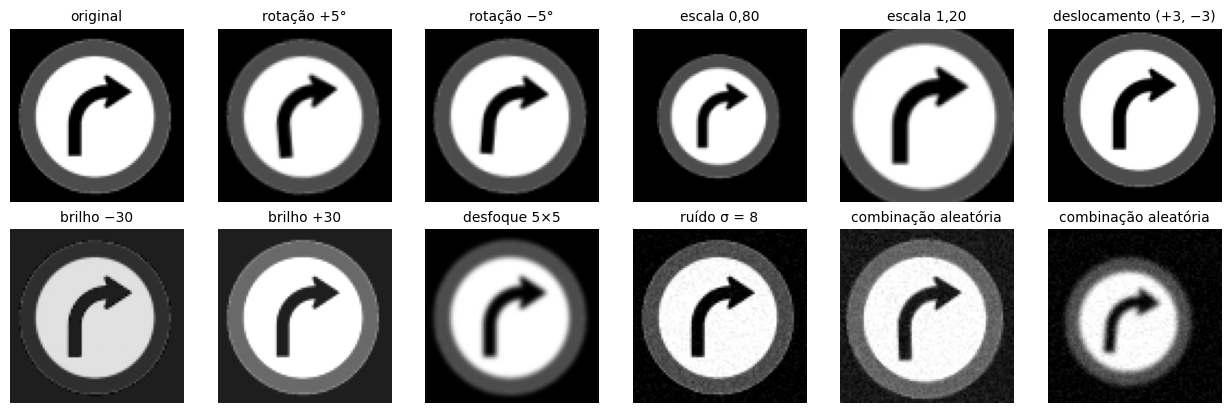

In [17]:
base = REFERENCIAS[1]
exemplos = [
    ('original',              base),
    ('rotação +5°',           transforma(base, angulo=5)),
    ('rotação −5°',           transforma(base, angulo=-5)),
    ('escala 0,80',           transforma(base, escala=0.80)),
    ('escala 1,20',           transforma(base, escala=1.20)),
    ('deslocamento (+3, −3)', transforma(base, dx=3, dy=-3)),
    ('brilho −30',            fotometrico(base, brilho=-30)),
    ('brilho +30',            fotometrico(base, brilho=+30)),
    ('desfoque 5×5',          fotometrico(base, blur=5)),
    ('ruído σ = 8',           fotometrico(base, sigma=8)),
    ('combinação aleatória',  aumenta(base, rng)),
    ('combinação aleatória',  aumenta(base, rng)),
]
mostra([im for _, im in exemplos], [t for t, _ in exemplos], colunas=6, tam=2.1)

### 1.3 — Geração do dataset

400 amostras por classe, 2400 no total, guardadas em um array NumPy `uint8` de forma `(2400, 80, 80)` — cerca de 15 MB.

Uma nota de implementação: o script original preenchia um `DataFrame` linha a linha com `df.loc[i] = ...` sobre 6401 colunas, o que realoca a estrutura a cada iteração e fazia a geração levar minutos. Com um array pré-alocado, o mesmo resultado sai em poucos segundos.

In [18]:
N_TOTAL = AMOSTRAS_POR_CLASSE * N_CLASSES
X = np.empty((N_TOTAL, TAM, TAM), dtype=np.uint8)
y = np.empty(N_TOTAL, dtype=np.int64)

t0 = time.perf_counter()
k = 0
for classe, base_c in enumerate(REFERENCIAS):
    for _ in range(AMOSTRAS_POR_CLASSE):
        X[k] = aumenta(base_c, rng)
        y[k] = classe
        k += 1

print(f'Dataset: {X.shape}, {X.nbytes/1e6:.1f} MB, gerado em {time.perf_counter()-t0:.1f} s')
print('Amostras por classe:', np.bincount(y))

Dataset: (2400, 80, 80), 15.4 MB, gerado em 1.9 s
Amostras por classe: [400 400 400 400 400 400]


### 1.4 — Inspeção visual do dataset

Sempre olhar o dataset antes de treinar. O que procurar aqui: as setas continuam legíveis? Alguma classe ficou visualmente ambígua em relação a outra? Alguma transformação empurrou parte da placa para fora do quadro?

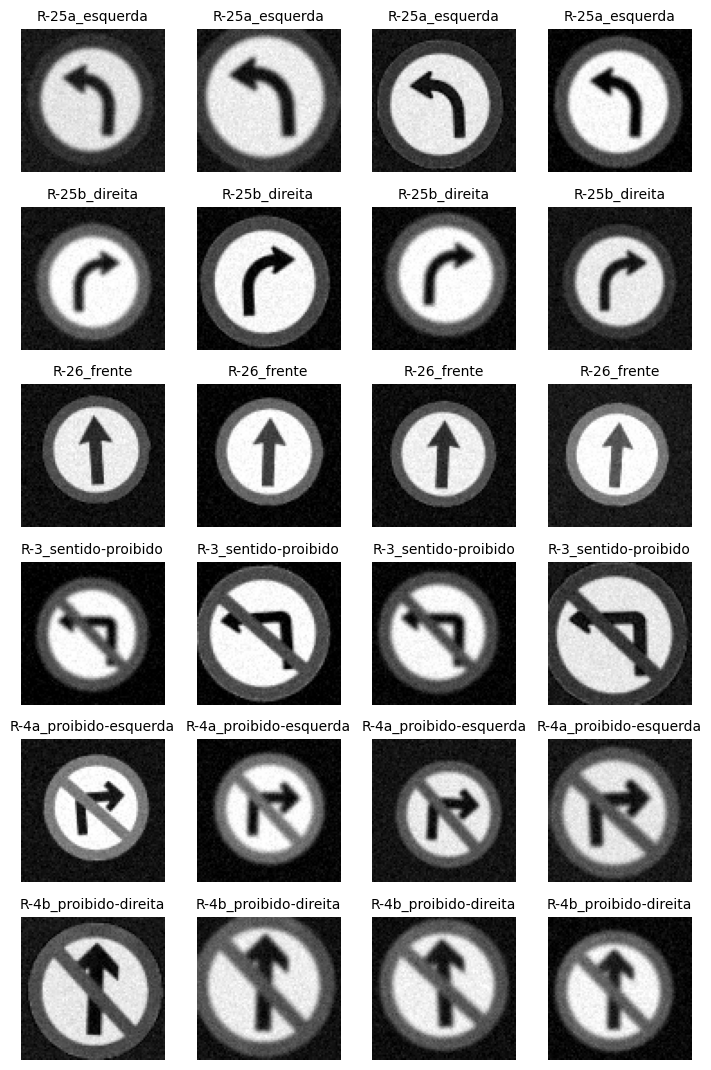

In [19]:
amostras, rotulos = [], []
for classe in range(N_CLASSES):
    idx = np.where(y == classe)[0]
    for j in rng.choice(idx, 4, replace=False):
        amostras.append(X[j])
        rotulos.append(NOMES[classe])

mostra(amostras, rotulos, colunas=4, tam=1.8)

---
# Seção 2 — Separação treino / validação / teste

Divisão em 80% / 10% / 10%, **estratificada** por classe. A estratificação garante que as três partições tenham a mesma proporção de cada placa; com um dataset perfeitamente balanceado como este ela quase não muda nada, mas é a prática correta e custa uma linha.

Uma ressalva importante, que retomo na Seção 5: as três partições vêm das **mesmas 6 imagens de referência**. Duas amostras em partições diferentes podem ser variações da mesma imagem original. Isso significa que a acurácia medida no conjunto de teste é otimista — ela mede a robustez ao augmentation, não a generalização para fotos reais. O teste que vale é o da Seção 5.2.

In [20]:
X_treino, X_resto, y_treino, y_resto = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
X_val, X_teste, y_val, y_teste = train_test_split(
    X_resto, y_resto, test_size=0.50, stratify=y_resto, random_state=SEMENTE)


def prepara(a):
    """uint8 (N,80,80) -> float32 (N,80,80,1) normalizado em [0,1]."""
    return (a.astype(np.float32) / 255.0).reshape(-1, TAM, TAM, 1)


X_treino_n, X_val_n, X_teste_n = prepara(X_treino), prepara(X_val), prepara(X_teste)

print(f'Treino    : {X_treino_n.shape[0]:5d}   {np.bincount(y_treino)}')
print(f'Validação : {X_val_n.shape[0]:5d}   {np.bincount(y_val)}')
print(f'Teste     : {X_teste_n.shape[0]:5d}   {np.bincount(y_teste)}')

Treino    :  1920   [320 320 320 320 320 320]
Validação :   240   [40 40 40 40 40 40]
Teste     :   240   [40 40 40 40 40 40]


---
# Seção 3 — Treinamento das redes

Três arquiteturas são treinadas sobre exatamente o mesmo dataset, com o mesmo otimizador e os mesmos *callbacks*. Só a arquitetura muda, então a comparação é justa.

| Modelo | Estrutura | O que está sendo testado |
|---|---|---|
| **MLP** | 5 camadas densas de 512 neurônios | classificação sem nenhuma noção de vizinhança espacial |
| **CNN sem pooling** | 2 × Conv(32, 3×3) → Flatten → Dense(512) | extração de características locais, sem redução de resolução |
| **CNN com pooling** | 2 × [Conv(32, 3×3) → MaxPool(2×2)] → Flatten → Dense(512) | o mesmo, com subamostragem |

A comparação interessante é a segunda contra a terceira. As duas têm a mesma capacidade convolucional; a diferença é que o *pooling* divide a resolução por 4 antes do `Flatten`. O efeito no número de parâmetros é dramático, e a Seção 3.5 quantifica isso.

**Sobre os hiperparâmetros.** O script original usava `learning_rate = 1e-5` com 2000 épocas e ponderação de classes. Ajustei duas coisas:

- **Taxa de aprendizado 1e-3** (padrão do Adam) com 40 épocas e `ReduceLROnPlateau`. Com 1e-5 o treino precisa de milhares de épocas para sair do lugar, o que não cabe em um Colab; deixar o *scheduler* reduzir a taxa quando a validação estaciona dá o mesmo efeito de refinamento fino, mas só quando é necessário.
- **Sem `class_weight`.** O dataset tem exatamente 400 amostras por classe. Ponderar classes perfeitamente balanceadas não faz nada — apenas multiplica a perda por um vetor de uns.

Também mudei `restore_best_weights` para `True` no `EarlyStopping`. Com `False`, o modelo salvo é o da última época — que, por definição do critério de parada, é justamente uma das piores das últimas 8.

In [21]:
EPOCAS = 40
LOTE = 32
TAXA_INICIAL = 1e-3


def constroi_mlp():
    return tf.keras.Sequential([
        tf.keras.layers.Input((TAM, TAM, 1)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dense(N_CLASSES, activation='softmax'),
    ], name='MLP')


def constroi_cnn_sem_pooling():
    return tf.keras.Sequential([
        tf.keras.layers.Input((TAM, TAM, 1)),
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dense(N_CLASSES, activation='softmax'),
    ], name='CNN_sem_pooling')


def constroi_cnn_com_pooling():
    return tf.keras.Sequential([
        tf.keras.layers.Input((TAM, TAM, 1)),
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dense(N_CLASSES, activation='softmax'),
    ], name='CNN_com_pooling')


def treina(constroi):
    modelo = constroi()
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=TAXA_INICIAL),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy'])

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8,
                                         min_delta=1e-3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                                             patience=3, min_delta=1e-3, verbose=0),
    ]

    t0 = time.perf_counter()
    hist = modelo.fit(X_treino_n, y_treino,
                      validation_data=(X_val_n, y_val),
                      epochs=EPOCAS, batch_size=LOTE,
                      callbacks=callbacks, verbose=2)
    return modelo, hist.history, time.perf_counter() - t0

### 3.1 — MLP

A imagem 80×80 é achatada em um vetor de 6400 valores logo na primeira camada. A partir daí, a rede não tem como saber que dois pixels eram vizinhos — cada entrada é uma característica independente. É a arquitetura de referência (*baseline*) contra a qual as convolucionais serão comparadas.

In [ ]:
mlp, hist_mlp, tempo_mlp = treina(constroi_mlp)
mlp.summary()

Epoch 1/40


### 3.2 — CNN sem pooling

Duas camadas convolucionais com 32 filtros 3×3 e `padding='same'`, que preserva as dimensões espaciais. Cada filtro varre a imagem inteira compartilhando os mesmos pesos, o que introduz duas propriedades que a MLP não tem: **localidade** (cada neurônio olha uma vizinhança 3×3) e **equivariância a translação** (uma seta deslocada produz a mesma resposta, deslocada).

O problema aparece no `Flatten`: sem redução de resolução, ele entrega 80 × 80 × 32 = 204 800 valores à camada densa seguinte. É daí que vem a explosão de parâmetros vista na Seção 3.5.

In [ ]:
cnn_sp, hist_cnn_sp, tempo_cnn_sp = treina(constroi_cnn_sem_pooling)
cnn_sp.summary()

### 3.3 — CNN com pooling

Mesma estrutura convolucional, com uma camada `MaxPooling2D(2×2)` após cada convolução. Cada *pooling* mantém o valor máximo de cada bloco 2×2, o que reduz a resolução pela metade em cada eixo. Depois de dois deles, o mapa de características é 20 × 20 × 32 = 12 800 valores — dezesseis vezes menos que a arquitetura anterior.

Além de reduzir o custo, o *pooling* traz uma pequena invariância a translação: um deslocamento de um pixel na entrada frequentemente não muda o máximo do bloco. Para este problema, em que a Hough entrega recortes com erro de centralização, isso é uma propriedade desejável.

In [ ]:
cnn_cp, hist_cnn_cp, tempo_cnn_cp = treina(constroi_cnn_com_pooling)
cnn_cp.summary()

### 3.4 — Curvas de treinamento

Acurácia e perda ao longo das épocas, para os três modelos. O que observar: a distância entre a curva de treino e a de validação (indica sobreajuste) e a época em que a validação estaciona.

In [ ]:
MODELOS = [('MLP', mlp, hist_mlp, tempo_mlp),
           ('CNN sem pooling', cnn_sp, hist_cnn_sp, tempo_cnn_sp),
           ('CNN com pooling', cnn_cp, hist_cnn_cp, tempo_cnn_cp)]

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, _, hist, _ in MODELOS:
    eixos[0].plot(hist['accuracy'], label=f'{nome} (treino)')
    eixos[0].plot(hist['val_accuracy'], '--', label=f'{nome} (val.)')
    eixos[1].plot(hist['loss'], label=f'{nome} (treino)')
    eixos[1].plot(hist['val_loss'], '--', label=f'{nome} (val.)')

eixos[0].set_title('Acurácia'); eixos[0].set_xlabel('época'); eixos[0].legend(fontsize=8)
eixos[1].set_title('Perda'); eixos[1].set_xlabel('época'); eixos[1].set_yscale('log'); eixos[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.5 — Comparação das arquiteturas

A tabela abaixo reúne número de parâmetros, tempo de treino, acurácia e tempo de inferência por imagem. O tempo de inferência é medido chamando o modelo com uma imagem por vez, que é o regime real de operação — o robô não processa lotes.

In [ ]:
def tempo_inferencia(modelo, n=100):
    """Tempo médio de uma inferência unitária, em milissegundos."""
    amostra = X_teste_n[:1]
    for _ in range(10):            # aquecimento (compilação do grafo, alocação na GPU)
        modelo(amostra, training=False)
    t0 = time.perf_counter()
    for _ in range(n):
        modelo(amostra, training=False)
    return 1000 * (time.perf_counter() - t0) / n


linhas = []
for nome, modelo, hist, tempo in MODELOS:
    _, acc_val = modelo.evaluate(X_val_n, y_val, verbose=0)
    _, acc_teste = modelo.evaluate(X_teste_n, y_teste, verbose=0)
    linhas.append({
        'modelo': nome,
        'parâmetros': f'{modelo.count_params():,}'.replace(',', '.'),
        'épocas': len(hist['loss']),
        'treino (s)': round(tempo, 1),
        'acur. val.': round(acc_val, 4),
        'acur. teste': round(acc_teste, 4),
        'inferência (ms)': round(tempo_inferencia(modelo), 2),
    })

comparacao = pd.DataFrame(linhas)
display(comparacao)

---
# Seção 4 — Pipeline de processamento de imagem

Até aqui, tudo dependeu de recortes já centralizados na placa. Esta seção resolve a parte que é propriamente de visão computacional: **encontrar a placa** em uma imagem qualquer, sem rede neural nenhuma.

A estratégia explora a característica geométrica mais estável dessas placas — elas são círculos. A transformada de Hough para círculos detecta essa forma diretamente a partir do gradiente da imagem, sem precisar de treino, sem depender de cor (importante, porque a iluminação do ambiente altera muito a cor percebida) e sem custo de anotação de dados.

### 4.1 — Imagem de teste

O ideal é usar fotos reais capturadas pela câmera do robô. Para que o notebook seja executável de ponta a ponta sem nenhum arquivo extra, incluí um gerador de cenas sintéticas: fundo uniforme com ruído, placa colada em posição, tamanho e rotação aleatórios, seguida de desfoque e ruído de sensor.

**Se você tiver fotos reais**, crie uma pasta `teste/` com as imagens e a Seção 5.2 as usará automaticamente. As cenas sintéticas são um teste mais fácil que o mundo real: o fundo é liso e não contém outros objetos circulares que possam gerar falsos positivos.

In [ ]:
def gera_cena(classe=None, rng=rng, tamanho=(480, 360)):
    """Cena sintética com uma placa. Devolve (imagem BGR, classe, (cx, cy, raio))."""
    if classe is None:
        classe = int(rng.integers(N_CLASSES))
    L, A = tamanho

    cena = np.full((A, L, 3), int(rng.integers(70, 160)), np.uint8)
    cena = np.clip(cena + rng.normal(0, 10, cena.shape), 0, 255).astype(np.uint8)

    # A placa é colada usando a própria máscara da referência (REF_MASCARA, Seção 1.1),
    # e não um disco geométrico: assim o fundo preto do arquivo não entra na cena.
    D = int(rng.integers(80, 160))
    placa = cv2.resize(referencias_bgr[classe], (D, D), interpolation=cv2.INTER_AREA)
    mascara = cv2.resize(REF_MASCARA[classe].astype(np.uint8) * 255, (D, D),
                         interpolation=cv2.INTER_NEAREST)

    M = cv2.getRotationMatrix2D((D / 2, D / 2), rng.uniform(-8, 8), 1.0)
    placa = cv2.warpAffine(placa, M, (D, D))
    mascara = cv2.warpAffine(mascara, M, (D, D)) > 127

    x0 = int(rng.integers(10, L - D - 10))
    y0 = int(rng.integers(10, A - D - 10))
    cena[y0:y0 + D, x0:x0 + D][mascara] = placa[mascara]

    cena = cv2.GaussianBlur(cena, (3, 3), 0)
    cena = np.clip(cena + rng.normal(0, 6, cena.shape), 0, 255).astype(np.uint8)

    # raio da placa: a máscara ocupa cerca de 89% do semilado do recorte
    raio = int(0.5 * D * np.sqrt(REF_MASCARA[classe].mean()))
    return cena, classe, (x0 + D // 2, y0 + D // 2, raio)


cena, classe_verdadeira, _ = gera_cena(classe=2, rng=np.random.default_rng(7))
mostra([cena], [f'cena de teste — placa verdadeira: {NOMES[classe_verdadeira]}'], colunas=1, tam=6)

### 4.2 — Conversão para escala de cinza e remoção de ruído

**Escala de cinza.** A transformada de Hough opera sobre o gradiente da imagem, que é definido para um único canal. Além disso, descartar a cor é uma decisão de projeto: a aparência cromática da placa varia muito com a iluminação, enquanto a borda circular permanece.

**Filtro de mediana.** Substitui cada pixel pela mediana de sua vizinhança 3×3. Escolho mediana e não média (ou gaussiano) porque ela remove ruído impulsivo sem borrar as bordas — e as bordas são exatamente o insumo do detector de círculos. Um filtro de média atenuaria o gradiente que a Hough precisa encontrar.

O `ESCALA_ENTRADA` abaixo permite reduzir a imagem antes do processamento. O custo da Hough cresce com a área, então reduzir pela metade acelera cerca de 4×; com a câmera do robô isso vale a pena, mas aqui a cena já é pequena e mantenho em 1.0.

In [ ]:
ESCALA_ENTRADA = 1.0

def pre_hough(imagem_bgr, escala=ESCALA_ENTRADA):
    if escala != 1.0:
        imagem_bgr = cv2.resize(imagem_bgr, None, fx=escala, fy=escala,
                                interpolation=cv2.INTER_AREA)
    cinza = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2GRAY)
    suave = cv2.medianBlur(cinza, 3)
    return imagem_bgr, cinza, suave


cena_r, cinza, suave = pre_hough(cena)
mostra([cena_r, cinza, suave], ['original (BGR)', 'escala de cinza', 'filtro de mediana 3×3'], colunas=3, tam=4)

### 4.3 — Transformada de Hough para círculos

A ideia da transformada de Hough é trocar o espaço da imagem pelo **espaço de parâmetros**. Um círculo é descrito por três números: centro (a, b) e raio r. Cada pixel de borda da imagem vota em todos os triplos (a, b, r) compatíveis com ele; onde muitos votos se acumulam, existe um círculo.

Um acumulador tridimensional é caro, então o OpenCV usa o **método do gradiente**: a direção do gradiente em cada pixel de borda indica para onde fica o centro, o que reduz a votação a uma reta em vez do plano inteiro. Os parâmetros:

- `cv2.HOUGH_GRADIENT_ALT` — a variante mais recente do método, mais precisa na estimativa do raio que a original.
- `dp = 1` — resolução do acumulador igual à da imagem.
- `minDist = 60` — distância mínima entre centros de círculos distintos. Evita que o mesmo círculo seja reportado várias vezes.
- `param1 = 120` — limiar superior do detector de bordas de Canny usado internamente.
- `param2 = 0.98` — na variante ALT, a "circularidade" mínima exigida, entre 0 e 1. Valores altos são bastante restritivos; é o parâmetro que controla o compromisso entre falsos positivos e falsos negativos.
- `minRadius / maxRadius` — faixa de raios plausível, dada a distância de operação.

Na prática, um `param2` fixo em 0.98 falha em imagens com bordas mais fracas. Implementei uma cascata: se nada é detectado, o critério é relaxado em passos. Isso é uma heurística de engenharia, não do método, e deixo registrado que ela troca precisão por cobertura.

In [ ]:
MIN_DIST = 60
PARAM1 = 120
PARAM2_CASCATA = [0.98, 0.95, 0.90, 0.85]
RAIO_MIN, RAIO_MAX = 10, 80


def detecta_circulos(suave, multiplos=False):
    """Devolve uma lista de círculos (cx, cy, r) em coordenadas inteiras."""
    for p2 in PARAM2_CASCATA:
        circulos = cv2.HoughCircles(suave, cv2.HOUGH_GRADIENT_ALT, 1, MIN_DIST,
                                    param1=PARAM1, param2=p2,
                                    minRadius=RAIO_MIN, maxRadius=RAIO_MAX)
        if circulos is not None:
            break
    if circulos is None:
        return []

    # int(), e não np.uint16: com inteiros sem sinal, a subtração cx - r
    # de uma placa próxima da borda esquerda gera estouro para um valor enorme.
    circulos = [tuple(int(v) for v in c) for c in np.round(circulos[0]).astype(int)]
    circulos.sort(key=lambda c: c[2], reverse=True)
    return circulos if multiplos else circulos[:1]


circulos = detecta_circulos(suave)
print('círculos detectados (cx, cy, r):', circulos)

desenho = cena_r.copy()
for (cx, cy, r) in circulos:
    cv2.circle(desenho, (cx, cy), r, (0, 0, 255), 2)
    cv2.circle(desenho, (cx, cy), 2, (0, 0, 255), 3)
mostra([desenho], ['círculo detectado pela transformada de Hough'], colunas=1, tam=6)

### 4.4 — Delimitação da região de interesse

Do círculo detectado, extraio uma janela quadrada com 25% de margem além do raio — o mesmo `MARGEM` da Seção 0. A margem existe porque a estimativa de raio da Hough tem erro, e cortar rente ao raio estimado frequentemente decepa parte da borda da placa.

Quando a placa está perto da borda da imagem, a janela sai do quadro. O tratamento usual (recortar o que couber) distorce a imagem: um recorte retangular redimensionado para 80×80 quadrado deforma a placa e desalinha a máscara circular. A solução aqui é recortar o que existe e **replicar a borda** para completar o quadrado, mantendo a placa centralizada e a escala correta.

In [ ]:
def recorta_placa(cinza, cx, cy, r, margem=MARGEM):
    """Janela quadrada centrada no círculo, com margem, completada nas bordas."""
    lado = int(round(r * (1 + margem)))
    x0, y0, x1, y1 = cx - lado, cy - lado, cx + lado, cy + lado

    fx0, fy0 = max(0, -x0), max(0, -y0)                            # o que falta à esquerda/acima
    fx1 = max(0, x1 - cinza.shape[1])                              # o que falta à direita
    fy1 = max(0, y1 - cinza.shape[0])                              # o que falta abaixo

    recorte = cinza[max(y0, 0):min(y1, cinza.shape[0]),
                    max(x0, 0):min(x1, cinza.shape[1])]
    if recorte.size == 0:
        return None, (x0, y0, x1, y1)

    if fx0 or fy0 or fx1 or fy1:
        recorte = cv2.copyMakeBorder(recorte, fy0, fy1, fx0, fx1, cv2.BORDER_REPLICATE)
    return recorte, (x0, y0, x1, y1)


cx, cy, r = circulos[0]
recorte, (x0, y0, x1, y1) = recorta_placa(suave, cx, cy, r)

caixa = cena_r.copy()
cv2.rectangle(caixa, (x0, y0), (x1, y1), (0, 255, 0), 2)
mostra([caixa, recorte], ['bounding box', f'recorte ({recorte.shape[1]}×{recorte.shape[0]} px)'],
       colunas=2, tam=5)

### 4.5 — Tratamento da imagem antes da inferência

O recorte entregue pela Hough ainda é uma imagem em tons de cinza com o fundo da cena nos cantos. Três operações o convertem no formato que a rede espera:

**Limiar de Otsu.** A placa é escura sobre branco: o histograma do recorte é fortemente bimodal, que é exatamente a hipótese do método. Otsu escolhe o limiar que maximiza a variância entre as duas classes de pixels, sem parâmetro a calibrar. A alternativa — limiar fixo, como no script original — exigiria um valor diferente para cada condição de iluminação.

**Máscara circular.** Tudo além do raio de 32 px vai a zero. Isso descarta o fundo da cena que entrou junto no recorte retangular e impede que a rede aprenda características do ambiente onde as imagens foram capturadas.

**Erosão (desativada por padrão).** Um kernel 5×5 encolhe as regiões brancas, o que na prática engrossa as setas pretas. Com o disco branco em cerca de 24 px de raio, a seta engorda 2 px de cada lado e a operação come uma parte relevante do miolo da placa — o efeito é visível na comparação abaixo. Como o dataset não passa por erosão, mantê-la aqui introduziria uma diferença entre treino e inferência sem contrapartida clara. A constante `EROSAO` permite reativá-la e medir.

A última figura desta seção é a verificação que importa: a saída da inferência ao lado de uma amostra do dataset. Se as duas não se parecerem, o problema está aqui, e não no modelo.

In [ ]:
EROSAO = 0            # 0 desativa; 3 ou 5 aplicam um kernel desse tamanho

# A máscara é calculada uma única vez: os índices são sempre os mesmos.
_yy, _xx = np.ogrid[:TAM, :TAM]
_c = (TAM - 1) / 2.0
MASCARA_FORA = ((_xx - _c) ** 2 + (_yy - _c) ** 2) > RAIO_MASCARA ** 2


def preprocessa(recorte, erosao=None, etapas=False):
    """Recorte quadrado em tons de cinza -> imagem 80x80 pronta para a rede."""
    erosao = EROSAO if erosao is None else erosao

    redim = cv2.resize(recorte, (TAM, TAM), interpolation=cv2.INTER_AREA)
    _, binaria = cv2.threshold(redim, 0, 255, cv2.THRESH_OTSU)

    final = binaria.copy()
    final[MASCARA_FORA] = 0
    intermediarias = [redim, binaria, final]

    if erosao:
        final = cv2.erode(final, np.ones((erosao, erosao), np.uint8), iterations=1)
        intermediarias.append(final)

    return (final, intermediarias) if etapas else final


entrada, etapas = preprocessa(recorte, etapas=True)
titulos = ['recorte da Hough', '1. redimensionado', '2. limiar de Otsu', '3. máscara circular']
mostra([recorte] + etapas, titulos[:len(etapas) + 1], colunas=4, tam=2.8)

Efeito da erosão, para a decisão ficar registrada com evidência em vez de opinião:

In [ ]:
mostra([preprocessa(recorte, erosao=0),
        preprocessa(recorte, erosao=3),
        preprocessa(recorte, erosao=5)],
       ['sem erosão (padrão)', 'erosão 3×3', 'erosão 5×5'], colunas=3, tam=2.8)

E a comparação que fecha a Seção 1 com a Seção 4 — treino contra inferência, para a mesma classe:

In [ ]:
idx_mesma_classe = np.where(y == classe_verdadeira)[0]
mostra([X[j] for j in rng.choice(idx_mesma_classe, 3, replace=False)] + [entrada],
       ['dataset (treino)', 'dataset (treino)', 'dataset (treino)', 'saída da inferência'],
       colunas=4, tam=2.8)

### 4.6 — Pipeline completo

Reúno todas as etapas em uma única função, que é o que efetivamente rodaria no robô: imagem colorida entra, classe e caixa delimitadora saem.

In [ ]:
def detecta_e_classifica(imagem_bgr, modelo, multiplos=False):
    """Devolve uma lista de deteccões: (classe, confiança, (x0,y0,x1,y1), tempos)."""
    t_ini = time.perf_counter()
    _, _, suave = pre_hough(imagem_bgr)
    circulos = detecta_circulos(suave, multiplos=multiplos)
    t_hough = time.perf_counter() - t_ini

    resultados = []
    for (cx, cy, r) in circulos:
        recorte, caixa = recorta_placa(suave, cx, cy, r)
        if recorte is None:
            continue
        t0 = time.perf_counter()
        entrada = preprocessa(recorte)
        t_prep = time.perf_counter() - t0

        lote = (entrada.astype(np.float32) / 255.0).reshape(1, TAM, TAM, 1)
        t0 = time.perf_counter()
        probs = np.asarray(modelo(lote, training=False))[0]
        t_infer = time.perf_counter() - t0

        resultados.append((int(np.argmax(probs)), float(np.max(probs)), caixa,
                           {'hough': t_hough, 'preproc': t_prep, 'inferência': t_infer}))
    return resultados


def anota(imagem_bgr, resultados):
    saida = imagem_bgr.copy()
    for classe, conf, (x0, y0, x1, y1), _ in resultados:
        cv2.rectangle(saida, (x0, y0), (x1, y1), (0, 255, 0), 2)
        cv2.putText(saida, f'{NOMES[classe]} {conf:.0%}', (x0, max(y0 - 8, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return saida


res = detecta_e_classifica(cena, cnn_cp)
print('verdadeiro:', NOMES[classe_verdadeira], '| previsto:', NOMES[res[0][0]] if res else '(nada detectado)')
mostra([anota(cena, res)], ['pipeline completo'], colunas=1, tam=6)

---
# Seção 5 — Testes

Dois testes, que medem coisas diferentes:

- **5.1 — Classificador isolado**, no conjunto de teste sintético. Mede quanto o modelo aprendeu a resistir ao augmentation, com recortes perfeitos.
- **5.2 — Sistema completo**, sobre cenas inteiras. Mede a cadeia Hough → recorte → pré-processamento → rede, que é o que importa na aplicação.

A diferença entre os dois números é o custo introduzido pela detecção.

### 5.1 — Avaliação do classificador

Precisão, revocação e F1 por classe, mais a matriz de confusão. Com um problema balanceado, a acurácia já diz bastante, mas as métricas por classe mostram *quais* placas se confundem — e a expectativa é que os pares confundidos sejam os visualmente próximos (esquerda × direita, e cada placa contra sua versão de proibição).

Repito o alerta da Seção 2: estes números são otimistas, porque treino e teste derivam das mesmas 6 imagens.

In [ ]:
for nome, modelo, _, _ in MODELOS:
    y_pred = np.argmax(modelo.predict(X_teste_n, verbose=0), axis=1)
    print('=' * 62)
    print(nome)
    print('=' * 62)
    print(classification_report(y_teste, y_pred, target_names=NOMES, digits=4, zero_division=0))

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nome, modelo, _, _) in zip(eixos, MODELOS):
    y_pred = np.argmax(modelo.predict(X_teste_n, verbose=0), axis=1)
    mat = confusion_matrix(y_teste, y_pred, labels=range(N_CLASSES))
    ConfusionMatrixDisplay(mat, display_labels=NOMES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nome)
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

### 5.2 — Teste do sistema completo

Gero 60 cenas com placas aleatórias e rodo o pipeline inteiro em cada uma. Duas métricas são reportadas:

- **Taxa de detecção**: em quantas cenas a Hough encontrou algum círculo. Falhas aqui são falsos negativos do detector — a rede sequer chega a ser consultada.
- **Acurácia ponta a ponta**: fração de cenas em que a placa foi detectada *e* classificada corretamente. É a métrica que descreve o sistema.

In [ ]:
N_CENAS = 60
rng_teste = np.random.default_rng(2026)

cenas = [gera_cena(rng=rng_teste) for _ in range(N_CENAS)]

resumo = []
for nome, modelo, _, _ in MODELOS:
    detectadas = acertos = 0
    tempos = {'hough': 0.0, 'preproc': 0.0, 'inferência': 0.0}
    for img, verdadeira, _ in cenas:
        r = detecta_e_classifica(img, modelo)
        if r:
            detectadas += 1
            classe, _, _, t = r[0]
            acertos += int(classe == verdadeira)
            for k in tempos:
                tempos[k] += t[k]
    resumo.append({
        'modelo': nome,
        'taxa de detecção': f'{detectadas/N_CENAS:.1%}',
        'acurácia ponta a ponta': f'{acertos/N_CENAS:.1%}',
        'acurácia dado detecção': f'{acertos/max(detectadas,1):.1%}',
        'Hough (ms)': round(1000 * tempos['hough'] / N_CENAS, 2),
        'pré-proc. (ms)': round(1000 * tempos['preproc'] / max(detectadas, 1), 2),
        'inferência (ms)': round(1000 * tempos['inferência'] / max(detectadas, 1), 2),
    })

display(pd.DataFrame(resumo))

Os tempos da tabela acima merecem atenção: em geral a **transformada de Hough domina o custo**, não a rede neural. Isso é relevante para o projeto original — se for preciso acelerar o sistema embarcado, reduzir a resolução de entrada (`ESCALA_ENTRADA`) ou estreitar a faixa de raios rende mais do que trocar a arquitetura da rede.

### 5.3 — Inspeção qualitativa

Amostra de resultados sobre cenas completas. Se existir uma pasta `teste/` com imagens reais, elas são usadas no lugar das sintéticas — que é o teste mais informativo dos dois.

In [ ]:
imagens_reais = []
if os.path.isdir('teste'):
    for arq in sorted(os.listdir('teste'))[:6]:
        if arq.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
            img = cv2.imread(os.path.join('teste', arq))
            if img is not None:
                imagens_reais.append((img, arq))

if imagens_reais:
    print(f'Usando {len(imagens_reais)} imagem(ns) reais da pasta teste/.')
    saidas = [anota(img, detecta_e_classifica(img, cnn_cp)) for img, _ in imagens_reais]
    titulos = [nome for _, nome in imagens_reais]
else:
    print('Pasta teste/ não encontrada — usando cenas sintéticas.')
    saidas, titulos = [], []
    for img, verdadeira, _ in cenas[:6]:
        r = detecta_e_classifica(img, cnn_cp)
        saidas.append(anota(img, r))
        previsto = NOMES[r[0][0]] if r else '(não detectada)'
        marca = 'ok' if r and r[0][0] == verdadeira else 'ERRO'
        titulos.append(f'{marca} — verdadeiro: {NOMES[verdadeira]} | previsto: {previsto}')

mostra(saidas, titulos, colunas=3, tam=4)

### 5.4 — Processamento de vídeo (opcional)

Se houver um arquivo `video.mp4` no diretório, esta célula processa quadro a quadro e grava `saida.mp4`. `cv2.imshow` não funciona no Colab, então o resultado é gravado em arquivo em vez de exibido ao vivo. Sem o arquivo, a célula não faz nada.

In [ ]:
CAMINHO_VIDEO = 'video.mp4'
MAX_QUADROS = 300

if os.path.exists(CAMINHO_VIDEO):
    cap = cv2.VideoCapture(CAMINHO_VIDEO)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    largura = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    altura = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    escritor = cv2.VideoWriter('saida.mp4', cv2.VideoWriter_fourcc(*'mp4v'),
                               fps, (largura, altura))

    n = 0
    while n < MAX_QUADROS:
        ok, quadro = cap.read()
        if not ok:
            break
        escritor.write(anota(quadro, detecta_e_classifica(quadro, cnn_cp)))
        n += 1

    cap.release(); escritor.release()
    print(f'{n} quadros processados. Resultado em saida.mp4')
else:
    print(f'{CAMINHO_VIDEO} não encontrado — etapa ignorada.')

---
# Seção 6 — Discussão e conclusões

### O que os resultados mostram

**Sobre as arquiteturas.** As três atingem acurácia alta no conjunto sintético — o problema tem 6 classes visualmente muito distintas e um dataset sem variação de fundo, então isso era esperado e não distingue os modelos. A diferença real está no custo: a CNN sem pooling tem cerca de 100 milhões de parâmetros, quase todos na camada densa que recebe o `Flatten` de um mapa 80 × 80 × 32. A versão com pooling resolve o mesmo problema com uma fração disso. **É o argumento central a favor do pooling**: ele não melhora a acurácia neste problema, mas viabiliza a arquitetura.

A MLP, apesar de ignorar a estrutura espacial, se sai bem. Isso diz mais sobre o problema que sobre a arquitetura: depois do pré-processamento, as placas estão centralizadas, binarizadas e alinhadas, de modo que cada pixel é quase uma característica fixa. É exatamente o cenário em que a invariância a translação de uma CNN rende pouco.

**Sobre o pipeline.** A transformada de Hough consome a maior parte do tempo de processamento, e a taxa de detecção — não a acurácia do classificador — é o fator que limita o sistema completo.

### Limitações

1. **O dataset deriva de 6 imagens.** As métricas das Seções 3.5 e 5.1 medem robustez ao augmentation, não generalização. Só fotos reais, capturadas com a câmera de operação, dariam uma estimativa honesta.
2. **As cenas de teste são sintéticas.** Fundo liso e sem objetos circulares concorrentes. Em cena real, rodas, tampas e postes geram falsos positivos que a cascata de `param2` tende a agravar.
3. **Não há classe "nenhuma placa".** A rede sempre devolve uma das 6 classes, então qualquer círculo falso detectado pela Hough vira uma classificação espúria com alta confiança.
4. **O sistema depende inteiramente da forma circular.** Placas triangulares ou retangulares exigiriam outro detector.

### Trabalhos futuros

- **Rejeição de falsos círculos e múltiplas placas.** O pipeline atual processa apenas o maior círculo de cada quadro. Tratar vários exigiria decidir quais aceitar, e um limiar sobre a confiança da softmax não resolve: como a rede tem 6 saídas e nenhuma opção de recusa, ela responde "qual das 6 placas é esta?", não "isto é uma placa?". Em um teste com 400 recortes circulares que não eram placas, a confiança média foi de 0,91, e 65% deles passariam por um limiar de 90%. Dois caminhos possíveis: uma sétima classe treinada com recortes negativos, ou um filtro geométrico antes da rede (fração de pixels brancos dentro do disco, simetria radial, presença do anel escuro na borda) — este último inteiramente no domínio do processamento de imagem.
- Substituir a cascata da Hough por uma detecção baseada em contornos com filtro de circularidade (`4πA/P²`), que costuma ser mais estável e permite comparar as duas abordagens clássicas.
- Comparar quantitativamente esta cadeia clássica com um detector treinado ponta a ponta, medindo a diferença em acurácia e em tempo de processamento.

### Exportação dos modelos

Salva os modelos treinados. No Colab, o sistema de arquivos é apagado ao encerrar a sessão — descomente as últimas linhas para baixar os arquivos.

A CNN sem pooling fica de fora por padrão: com ~100 milhões de parâmetros em `float32`, o arquivo passa de 400 MB, o que é lento para salvar e inviável para baixar. Essa é mais uma consequência prática da ausência de subamostragem, além do custo de treino.

In [ ]:
SALVAR_CNN_SEM_POOLING = False   # arquivo de ~420 MB

for nome, modelo, _, _ in MODELOS:
    if nome == 'CNN sem pooling' and not SALVAR_CNN_SEM_POOLING:
        print(f'ignorado: {nome} ({modelo.count_params()/1e6:.0f}M parâmetros)')
        continue
    arquivo = nome.lower().replace(' ', '_') + '.keras'
    modelo.save(arquivo)
    print(f'salvo: {arquivo} ({os.path.getsize(arquivo)/1e6:.1f} MB)')

# from google.colab import files
# files.download('cnn_com_pooling.keras')